# Forecasting Revenue per Jam per Cabang — Machine Learning & Deep Learning
**Kelompok 04 · Tema: Tren Penjualan Coffee Shop (Maven Roasters)**

Notebook ini melanjutkan `eda.ipynb`. Kalau EDA menjawab *"apa yang sudah terjadi?"*, notebook ini menjawab
*"berapa revenue yang akan masuk satu jam ke depan di tiap cabang?"*.

## 1. Masalah
Manajer cabang butuh perkiraan revenue per jam untuk mengatur jumlah barista per shift dan stok bahan.
Tugas kita: **memprediksi revenue 1 jam ke depan untuk tiap cabang** (Astoria, Hell's Kitchen, Lower Manhattan).
Ini termasuk **regresi time series**: targetnya angka (dolar) yang berurutan menurut waktu.

Kita membandingkan tiga pendekatan:

| # | Model | Jenis |
|---|---|---|
| 1 | Seasonal naive | Baseline (tanpa belajar) |
| 2 | Random Forest Regressor | Machine Learning (scikit-learn) |
| 3 | LSTM | Deep Learning (PyTorch, CPU) |

Semua kode ada di `src/forecasting.py`; notebook ini memanggil fungsi-fungsinya langkah demi langkah.
Untuk melatih ulang **dan menyimpan** model serta hasil yang dibaca dashboard, jalankan `python train_models.py`.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src import processing as P
from src import forecasting as F

pd.set_option("display.float_format", "{:,.2f}".format)
COLORS = {"aktual": "#2a78d6", "seasonal_naive": "#8a8985", "random_forest": "#eb6834", "lstm": "#1baf7a"}
NAMES = {"aktual": "Aktual", **F.MODELS}

2026-10-28 13:53:22.687 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


## 2. Data: revenue per jam per cabang
Data transaksi (±149 ribu baris) diagregasi menjadi **total revenue per jam per cabang**.

- Jam tanpa transaksi diisi **0**, tetapi hanya di **rentang jam buka** tiap cabang (jam pertama sampai jam terakhir
  yang pernah ada transaksi di data train). Jam tutup tidak ikut dilatih maupun dievaluasi.
- Supaya "24 jam lalu" dan "168 jam lalu" selalu berarti *jam yang sama kemarin / minggu lalu*, data disimpan di grid
  24 jam penuh (jam tutup bernilai 0) dan kolom `buka` menandai jam buka.

In [2]:
df = P.add_features(P.load_data())
h = F.hourly_series(df)
print(f"Grid: {len(h):,} baris = 3 cabang × {h['ts'].nunique():,} jam ({h['ts'].min()} s.d. {h['ts'].max()})")
print(f"Jam buka: {h['buka'].sum():,} baris")
display(h[h["buka"]].groupby("store_location")["jam"].agg(["min", "max"]).rename(columns={"min": "jam buka", "max": "jam terakhir"}))
assert abs(h["revenue"].sum() - df["revenue"].sum()) < 1e-6  # agregasi tidak kehilangan revenue
h[h["buka"]].head()

Grid: 13,032 baris = 3 cabang × 4,344 jam (2023-01-01 00:00:00 s.d. 2023-06-30 23:00:00)
Jam buka: 7,783 baris


,jam buka,jam terakhir
store_location,,
Astoria,7,19
Hell's Kitchen,6,20
Lower Manhattan,6,20


,store_location,ts,revenue,jam,hari_ke,buka
7,Astoria,2023-01-01 07:00:00,0.00,7,6,True
8,Astoria,2023-01-01 08:00:00,0.00,8,6,True
9,Astoria,2023-01-01 09:00:00,0.00,9,6,True
10,Astoria,2023-01-01 10:00:00,0.00,10,6,True
11,Astoria,2023-01-01 11:00:00,98.90,11,6,True


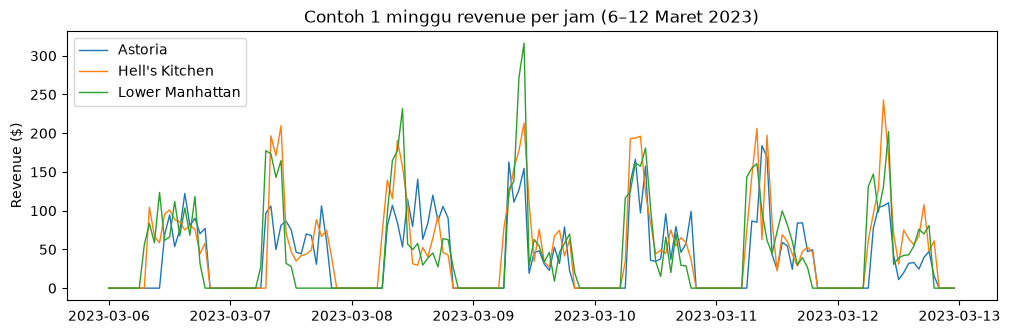

In [3]:
fig, ax = plt.subplots(figsize=(12, 3.5))
for s, g in h[(h["ts"] >= "2023-03-06") & (h["ts"] < "2023-03-13")].groupby("store_location"):
    ax.plot(g["ts"], g["revenue"], label=s, lw=1)
ax.set(title="Contoh 1 minggu revenue per jam (6–12 Maret 2023)", ylabel="Revenue ($)")
ax.legend(); plt.show()

Terlihat pola **harian** yang kuat (puncak pagi pukul 07–10, lalu turun) dan pola yang mirip dari hari ke hari.
Inilah alasan fitur jam, hari, dan lag 24/168 jam dipakai.

## 3. Split berdasarkan waktu
Pada time series kita **tidak boleh split acak**: kalau acak, model bisa "mengintip" jam-jam di masa depan
yang berdekatan dengan jam yang diuji. Jadi:

- **Train:** 1 Januari – 31 Mei 2023
- **Validation (khusus LSTM):** 2 minggu terakhir data train, 18 – 31 Mei 2023 (untuk early stopping)
- **Test:** 1 – 30 Juni 2023 (tidak pernah dilihat saat training)

In [4]:
h = F.add_lag_features(h)
train, test = F.split(h)
val = train[train["ts"] >= F.VAL_START]
for name, d in [("Train (termasuk validation)", train), ("  - validation LSTM", val), ("Test", test)]:
    print(f"{name:30s} {d['ts'].min():%d %b %Y} – {d['ts'].max():%d %b %Y %H:%M}  ({len(d):,} jam-cabang)")
assert train["ts"].max() < test["ts"].min()

Train (termasuk validation)    01 Jan 2023 – 31 May 2023 20:00  (6,493 jam-cabang)
  - validation LSTM            18 May 2023 – 31 May 2023 20:00  (602 jam-cabang)
Test                           01 Jun 2023 – 30 Jun 2023 20:00  (1,290 jam-cabang)


## 4. Fitur (untuk Random Forest)

| Fitur | Arti |
|---|---|
| `jam`, `hari_ke` | jam (0–23) dan hari dalam seminggu (0 = Senin) |
| `cabang_*` | one-hot cabang (3 kolom 0/1) |
| `lag_1` | revenue 1 jam sebelumnya |
| `lag_24` | revenue jam yang sama kemarin |
| `lag_168` | revenue jam yang sama minggu lalu |
| `roll_mean_24` | rata-rata revenue 24 jam terakhir (tidak termasuk jam yang diprediksi) |

**Menghindari data leakage:** semua fitur revenue di-*shift* minimal 1 jam per cabang, jadi saat memprediksi jam *t*
model hanya melihat data sampai jam *t−1*. Rolling mean juga di-shift dulu baru dirata-rata.
Sel berikut membuktikannya.

In [5]:
a = h[h["store_location"] == "Astoria"].set_index("ts")
t = pd.Timestamp("2023-04-12 09:00")
assert a.loc[t, "lag_1"] == a.loc[t - pd.Timedelta(hours=1), "revenue"]
assert a.loc[t, "lag_168"] == a.loc[t - pd.Timedelta(days=7), "revenue"]
assert np.isclose(a.loc[t, "roll_mean_24"], a.loc[t - pd.Timedelta(hours=24): t - pd.Timedelta(hours=1), "revenue"].mean())
print("OK: fitur jam", t, "hanya memakai data sebelum", t)
train[F.RF_FEATURES + ["revenue"]].dropna().head()

OK: fitur jam 2023-04-12 09:00:00 hanya memakai data sebelum 2023-04-12 09:00:00


,jam,hari_ke,cabang_Astoria,cabang_Hell's Kitchen,cabang_Lower Manhattan,lag_1,lag_24,lag_168,roll_mean_24,revenue
175,7,6,1,0,0,0.00,83.35,0.00,33.64,18.00
176,8,6,1,0,0,18.00,92.55,0.00,30.91,74.85
177,9,6,1,0,0,74.85,12.25,0.00,30.18,31.40
178,10,6,1,0,0,31.40,64.75,0.00,30.97,73.50
179,11,6,1,0,0,73.50,69.25,98.90,31.34,74.15


## 5. Model 1 — Baseline: Seasonal Naive
Prediksi = **revenue pada jam yang sama 7 hari sebelumnya** (`lag_168`). Model ini tidak belajar apa pun, tapi sering
sulit dikalahkan pada data yang pola mingguannya kuat. Model ML/DL baru dianggap berguna kalau **lebih baik dari baseline ini**.

## 6. Model 2 — Machine Learning: Random Forest Regressor
**Cara kerja:**
1. *Decision tree* memecah data dengan pertanyaan ya/tidak berulang (mis. "jam ≤ 10?", "lag_1 > $300?") sampai tiap
   daun berisi jam-jam yang revenuenya mirip; prediksi = rata-rata revenue di daun itu.
2. Satu pohon mudah *overfitting*. Random Forest melatih **banyak pohon (di sini 300)**, masing-masing dengan
   **sampel bootstrap** (diambil acak dengan pengembalian) dan **subset fitur acak** di tiap percabangan.
3. Prediksi akhir = **rata-rata prediksi semua pohon**. Rata-rata dari banyak pohon yang berbeda menurunkan varians.

RF tidak butuh normalisasi karena hanya membandingkan nilai fitur dengan ambang batas.
`n_jobs=1` dan `random_state=42` dipakai supaya hasil training identik persis setiap kali dijalankan.

### Tuning hyperparameter dengan TimeSeriesSplit
Tiga hyperparameter dicoba dengan *grid search* (2 × 3 × 4 = 24 kombinasi):

| Hyperparameter | Arti | Nilai yang dicoba |
|---|---|---|
| `n_estimators` | jumlah pohon | 100, 300 |
| `max_depth` | kedalaman maksimum pohon (None = tanpa batas) | None, 10, 20 |
| `min_samples_leaf` | jumlah sampel minimum di tiap daun | 1, 3, 5, 10 |

Validasinya memakai **`TimeSeriesSplit` (5 fold) di data train saja**. Data Januari–Mei diurutkan menurut waktu, lalu
fold ke-*k* dilatih pada bagian awal dan divalidasi pada potongan **sesudahnya**. Dengan begitu tuning tidak pernah
melihat data test Juni dan tidak pernah memakai masa depan untuk memprediksi masa lalu. Kombinasi dengan rata-rata
RMSE validasi terendah dipilih, lalu dilatih ulang pada seluruh data train.

,param_n_estimators,param_max_depth,param_min_samples_leaf,RMSE validasi
13,300,10,5,45.07
21,300,20,5,45.08
5,300,None,5,45.08
12,100,10,5,45.15
20,100,20,5,45.15
4,100,None,5,45.16
15,300,10,10,45.23
7,300,None,10,45.23


Parameter terbaik: {'max_depth': 10, 'min_samples_leaf': 5, 'n_estimators': 300} | RMSE validasi 45.07


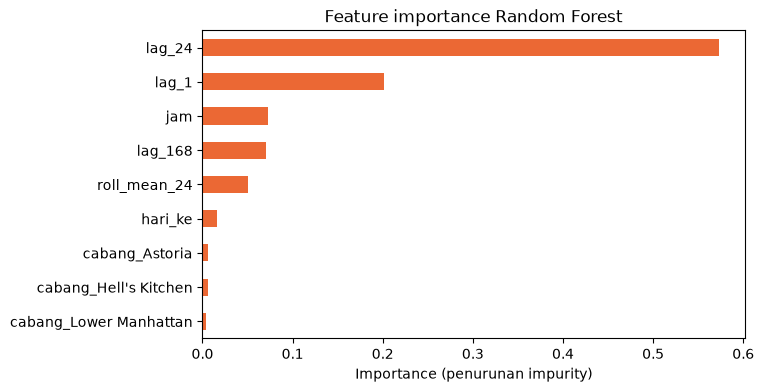

In [6]:
gs = F.tune_rf(train)
cv = pd.DataFrame(gs.cv_results_)
cv["RMSE validasi"] = -cv["mean_test_score"]
display(cv.sort_values("RMSE validasi")[["param_n_estimators", "param_max_depth", "param_min_samples_leaf", "RMSE validasi"]].head(8))
print("Parameter terbaik:", gs.best_params_, f"| RMSE validasi {-gs.best_score_:.2f}")
rf = gs.best_estimator_
rf_default = F.train_rf(train)  # pembanding: parameter sebelum tuning (300 pohon, tanpa batas kedalaman, daun min. 3)
imp = pd.Series(rf.feature_importances_, index=F.RF_FEATURES).sort_values()
imp.plot.barh(figsize=(7, 4), color="#eb6834", title="Feature importance Random Forest")
plt.xlabel("Importance (penurunan impurity)"); plt.show()

## 7. Model 3 — Deep Learning: LSTM (PyTorch)
**LSTM (Long Short-Term Memory)** adalah jenis *recurrent neural network* yang membaca data berurutan langkah demi
langkah sambil menyimpan "memori" (*cell state*). Di tiap langkah ada tiga *gate*:
- **forget gate**: informasi lama mana yang dibuang,
- **input gate**: informasi baru mana yang disimpan ke memori,
- **output gate**: bagian memori mana yang dikeluarkan sebagai *hidden state*.

Gate inilah yang membuat LSTM mampu mengingat pola jangka lebih panjang dibanding RNN biasa.

**Arsitektur yang dipakai:**
1. Input berurutan: **window 48 jam terakhir**, tiap langkah berisi revenue (ter-normalisasi) + sin/cos jam → `(48, 3)`.
2. `LSTM(hidden=64)` membaca 48 langkah itu; *hidden state* terakhir = ringkasan 2 hari terakhir.
3. Ringkasan digabung dengan fitur jam yang diprediksi (sin/cos jam & hari) dan one-hot cabang (7 nilai).
4. `Linear(71→32) → ReLU → Linear(32→1)` = prediksi revenue 1 jam ke depan.

**Training:**
- **Normalisasi**: revenue dikurangi mean lalu dibagi standar deviasi, dengan mean/std dihitung **hanya dari data train**
  (sebelum 18 Mei) supaya informasi validation/test tidak bocor.
- Loss MSE, optimizer Adam (lr 0,001), batch 128.
- **Early stopping**: tiap epoch dihitung loss validation; training berhenti kalau 10 epoch berturut-turut tidak membaik,
  lalu bobot dikembalikan ke epoch dengan validation loss terendah.
- **Reproducibility**: `torch.manual_seed(42)`, urutan batch dari `numpy` dengan seed 42, dan
  `torch.use_deterministic_algorithms(True)`.

Training di CPU butuh beberapa menit.

Berhenti di epoch 53, epoch terbaik 43 (val loss 0.6325)
Scaler (dari data train): {'mean': 46.65, 'std': 64.12}


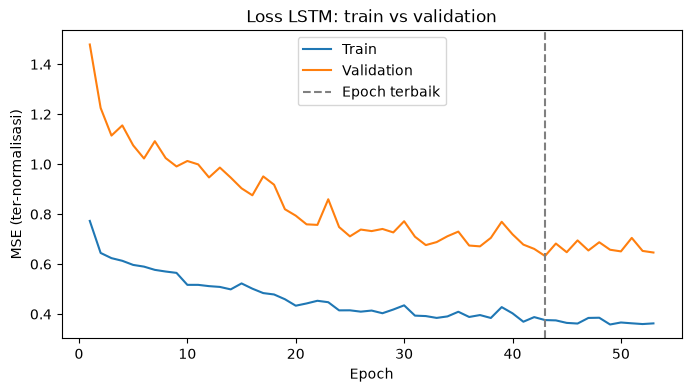

In [7]:
lstm, loss, scaler = F.train_lstm(h)
best = loss.loc[loss["best"]].iloc[0]
print(f"Berhenti di epoch {len(loss)}, epoch terbaik {int(best['epoch'])} (val loss {best['val_loss']:.4f})")
print("Scaler (dari data train):", {k: round(v, 2) for k, v in scaler.items()})

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(loss["epoch"], loss["train_loss"], label="Train")
ax.plot(loss["epoch"], loss["val_loss"], label="Validation")
ax.axvline(best["epoch"], color="gray", ls="--", label="Epoch terbaik")
ax.set(xlabel="Epoch", ylabel="MSE (ter-normalisasi)", title="Loss LSTM: train vs validation"); ax.legend(); plt.show()

## 8. Evaluasi di data test (Juni 2023)
Ketiga model memprediksi **1 jam ke depan** untuk setiap jam buka di bulan Juni. Riwayat yang dipakai (lag, window)
adalah data aktual sampai jam sebelumnya, sama seperti kondisi nyata ketika prediksi dibuat tiap jam.

Metrik:
- **MAE** (*Mean Absolute Error*): rata-rata selisih absolut, dalam dolar.
- **RMSE** (*Root Mean Squared Error*): seperti MAE tapi menghukum kesalahan besar lebih berat.
- **MAPE** (*Mean Absolute Percentage Error*): rata-rata selisih dalam persen. Jam dengan aktual 0 diabaikan
  (pembagian dengan nol). MAPE per jam cenderung besar karena ada jam sepi dengan revenue kecil.

In [8]:
res = F.build_results(h, test, rf, lstm, scaler)
metrics = F.evaluate(res)
hourly = metrics[metrics["level"] == "jam"]
display(hourly.pivot(index="model", columns="cabang", values=["MAE", "RMSE", "MAPE"]).round(2))

MAE                                         RMSE  \
cabang         Astoria Hell's Kitchen Lower Manhattan Semua Astoria   
model                                                                 
LSTM             41.08          41.83           40.73 41.22   57.46   
Random Forest    42.07          42.05           36.25 40.03   57.94   
Seasonal Naive   94.81          63.88           56.34 70.60  118.41   

                                                       MAPE                 \
cabang         Hell's Kitchen Lower Manhattan Semua Astoria Hell's Kitchen   
model                                                                        
LSTM                    64.74           55.80 59.55   31.35          32.07   
Random Forest           65.40           51.61 58.62   33.38          34.14   
Seasonal Naive          95.63           84.60 99.63   78.28          56.16   

                                      
cabang         Lower Manhattan Semua  
model                                 
LSTM                     34.62 32.68  
Random Forest            33.58 33.71  
Seasonal Naive           54.25 62.61

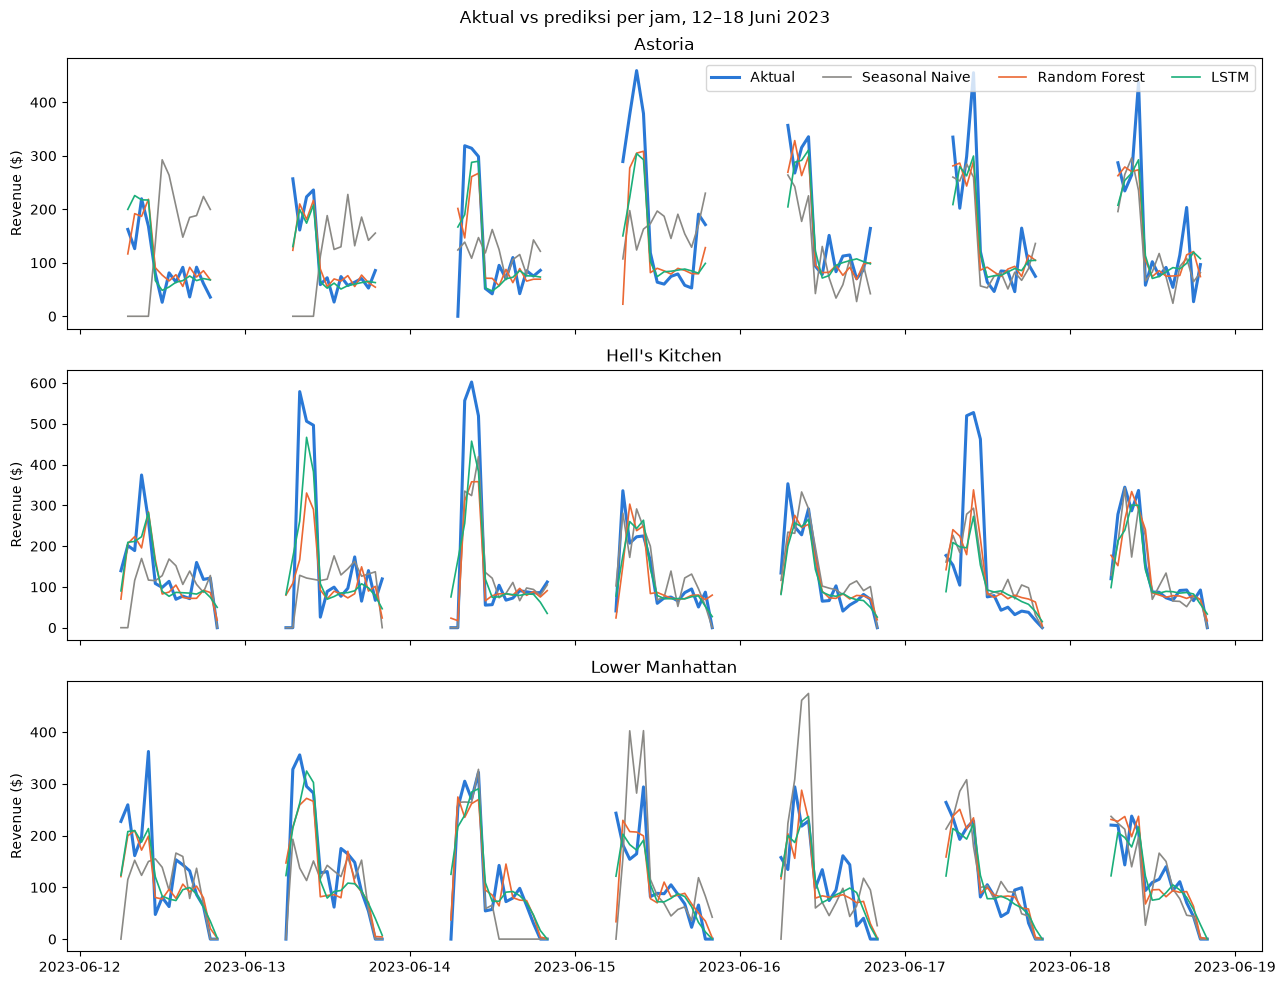

In [9]:
fig, axes = plt.subplots(3, 1, figsize=(13, 10), sharex=True)
week = res[(res["ts"] >= "2023-06-12") & (res["ts"] < "2023-06-19")]
for ax, (s, g) in zip(axes, week.groupby("store_location")):
    g = g.set_index("ts").reindex(pd.date_range("2023-06-12", "2023-06-19", freq="h", inclusive="left"))
    for col in NAMES:
        ax.plot(g.index, g[col], label=NAMES[col], color=COLORS[col], lw=2.2 if col == "aktual" else 1.2)
    ax.set(title=s, ylabel="Revenue ($)")
axes[0].legend(ncol=4, loc="upper right")
fig.suptitle("Aktual vs prediksi per jam, 12–18 Juni 2023"); fig.tight_layout(); plt.show()

### Agregasi ke level harian
Prediksi per jam dijumlahkan menjadi total per hari per cabang, lalu dibandingkan dengan revenue aktual harian.
Ini relevan untuk perencanaan harian (stok bahan), dan kesalahan per jam yang acak sebagian saling menutupi.

### Apakah tuning membantu?
Random Forest sebelum tuning (`n_estimators=300, max_depth=None, min_samples_leaf=3`) dibandingkan dengan hasil tuning
di data test yang sama.

In [10]:
rows, bp = [], gs.best_params_
for name, p in [("Default (300, None, 3)", rf_default.predict(test[F.RF_FEATURES])), (f"Tuned ({bp['n_estimators']}, {bp['max_depth']}, {bp['min_samples_leaf']})", res["random_forest"].to_numpy())]:
    x = res.assign(random_forest=p); dd = F.daily(x)
    j, k = F.scores(x["aktual"].to_numpy(), p), F.scores(dd["aktual"].to_numpy(), dd["random_forest"].to_numpy())
    rows.append({"Random Forest": name, **{f"{m} jam": j[m] for m in j}, **{f"{m} hari": k[m] for m in k}})
pd.DataFrame(rows).round(2)

,Random Forest,MAE jam,RMSE jam,MAPE jam,MAE hari,RMSE hari,MAPE hari
0,"Default (300, None, 3)",40.07,58.69,33.54,187.76,248.83,9.67
1,"Tuned (300, 10, 5)",40.03,58.62,33.71,184.80,245.21,9.50


MAE                                          RMSE  \
cabang         Astoria Hell's Kitchen Lower Manhattan  Semua Astoria   
model                                                                  
LSTM            217.73         188.09          199.99 201.94  266.15   
Random Forest   199.16         195.83          159.42 184.80  251.96   
Seasonal Naive  277.76         345.38          363.27 328.80  379.72   

                                                        MAPE                 \
cabang         Hell's Kitchen Lower Manhattan  Semua Astoria Hell's Kitchen   
model                                                                         
LSTM                   254.36          237.72 253.01   11.31           9.30   
Random Forest          269.41          210.52 245.21   10.41           9.52   
Seasonal Naive         414.17          408.72 401.16   14.78          18.49   

                                      
cabang         Lower Manhattan Semua  
model                                 
LSTM                     10.61 10.41  
Random Forest             8.56  9.50  
Seasonal Naive           20.53 17.93

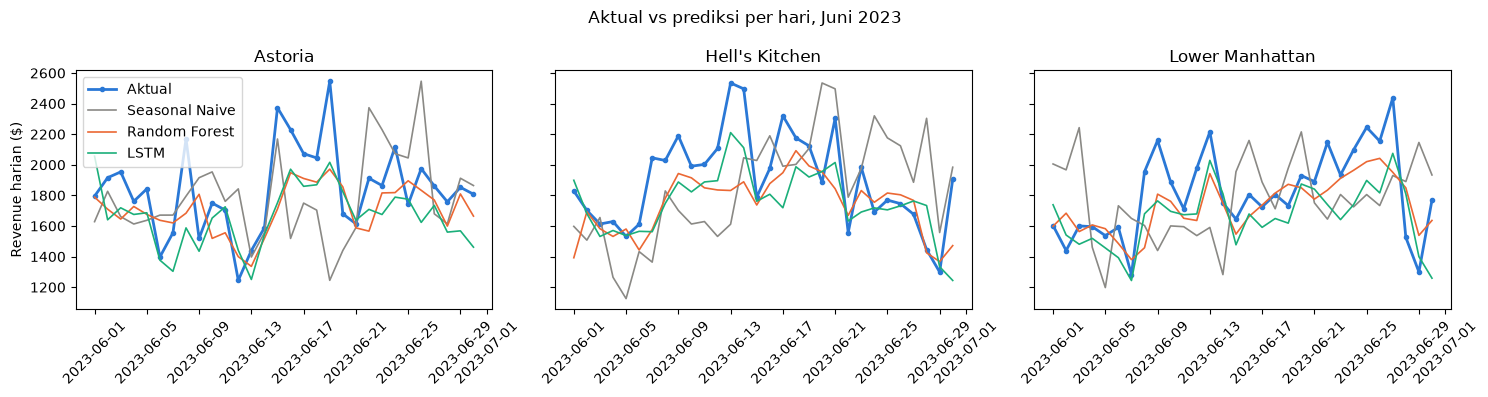

In [11]:
d = F.daily(res)
display(metrics[metrics["level"] == "hari"].pivot(index="model", columns="cabang", values=["MAE", "RMSE", "MAPE"]).round(2))
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, (s, g) in zip(axes, d.groupby("store_location")):
    for col in NAMES:
        ax.plot(g["tanggal"], g[col], label=NAMES[col], color=COLORS[col], marker="o" if col == "aktual" else None,
                ms=3, lw=2 if col == "aktual" else 1.2)
    ax.set_title(s); ax.tick_params(axis="x", rotation=45)
axes[0].set_ylabel("Revenue harian ($)"); axes[0].legend()
fig.suptitle("Aktual vs prediksi per hari, Juni 2023"); fig.tight_layout(); plt.show()

## 9. Ringkasan metrik

In [12]:
summary = metrics[metrics["cabang"] == "Semua"].pivot(index="model", columns="level", values=["MAE", "RMSE", "MAPE"])
summary.round(2)

MAE         RMSE        MAPE      
level            hari   jam   hari   jam  hari   jam
model                                               
LSTM           201.94 41.22 253.01 59.55 10.41 32.68
Random Forest  184.80 40.03 245.21 58.62  9.50 33.71
Seasonal Naive 328.80 70.60 401.16 99.63 17.93 62.61

## 10. Kesimpulan

**Hasil di data test Juni 2023 (semua cabang):**

| Model | MAE per jam | RMSE per jam | MAPE per jam | RMSE per hari | MAPE per hari |
|---|---|---|---|---|---|
| Seasonal Naive | \$70,60 | \$99,63 | 62,6% | \$401,16 | 17,9% |
| **Random Forest (tuned)** | **\$40,03** | **\$58,62** | 33,7% | **\$245,21** | **9,5%** |
| LSTM | \$41,22 | \$59,55 | **32,7%** | \$253,01 | 10,4% |

1. **Kedua model yang belajar jauh lebih baik dari baseline.** RMSE per jam turun ±41% (Random Forest) dan ±40% (LSTM)
   dibanding seasonal naive. Seasonal naive hanya menyalin satu jam dari minggu lalu, jadi ikut menyalin hari yang
   tidak biasa (contoh: Astoria tanpa transaksi pukul 07–10 pada 5 Juni ikut "diprediksi" untuk 12 Juni) dan tidak
   mengikuti tren revenue yang terus naik dari Januari ke Juni. Random Forest dan LSTM melihat kondisi terbaru
   (lag 1 jam, rata-rata 24 jam, window 48 jam) dan belajar pola jam sibuk dari 5 bulan data.
2. **Random Forest adalah model terbaik secara keseluruhan**, dengan MAE dan RMSE terendah baik per jam maupun per hari.
   Selisihnya dengan LSTM **sangat kecil** (RMSE per jam \$58,62 vs \$59,55). LSTM sedikit lebih baik di MAPE per jam
   dan di cabang Astoria & Hell's Kitchen, sedangkan Random Forest unggul jelas di Lower Manhattan.
3. **Tuning hyperparameter hanya memberi perbaikan kecil.** TimeSeriesSplit memilih `n_estimators=300, max_depth=10,
   min_samples_leaf=5`. Pohon yang lebih dangkal dengan daun lebih besar sedikit mengurangi *overfitting*. Di test,
   RMSE per jam hanya turun dari \$58,69 ke \$58,62 (0,1%) dan MAPE per jam malah naik tipis (33,5% → 33,7%), sedangkan
   RMSE per hari turun dari \$248,83 ke \$245,21 (1,5%). Artinya parameter awal sudah cukup baik; keterbatasan utamanya
   ada di informasi pada fitur, bukan di pengaturan model.
4. **Kenapa Random Forest sedikit unggul dari LSTM?** Datanya tabular dan relatif kecil (±6.500 jam-cabang untuk training).
   Pola terpentingnya (jam, hari, level revenue terakhir) sudah diberikan secara eksplisit sebagai fitur, dan pohon
   keputusan mudah menangkap aturan seperti "jam 7–10 pagi = sibuk". LSTM harus menemukan pola itu sendiri dari urutan
   angka, sehingga butuh data lebih banyak untuk benar-benar unggul.
5. **Rekomendasi:** pakai **Random Forest**. Akurasinya setara atau lebih baik, training hanya beberapa detik, tidak perlu
   normalisasi, mudah dijelaskan lewat *feature importance*, dan tidak membutuhkan PyTorch.
6. **Level harian jauh lebih akurat** (MAPE ±10% vs ±33% per jam), karena kesalahan per jam yang acak sebagian saling
   menutupi saat dijumlahkan. MAPE per jam besar terutama karena jam-jam sepi dengan revenue kecil, di mana selisih
   beberapa dolar saja sudah menjadi persentase besar.

**Keterbatasan:**
- Prediksi hanya **1 jam ke depan** dengan riwayat aktual. Untuk meramal beberapa hari ke depan dibutuhkan prediksi
  rekursif atau multi-step, dan akurasinya akan turun.
- Data hanya 6 bulan, jadi pola musiman tahunan (libur, cuaca) belum terlihat.
- RMSE validasi saat tuning (\$45) lebih kecil dari RMSE test (\$59) karena revenue Juni lebih tinggi daripada rata-rata
  Januari–Mei, sehingga kesalahan dalam dolar ikut membesar.
- LSTM belum di-*tuning* (satu konfigurasi saja).
